Voer alleen cijfers in
Voer een geldig getal in
Voer een geldig getal in
Voer een geldig getal in
Minimum moet kleiner zijn dan Maximum
Uitschieters: [-13.28, 22.37, 18.19, -7.25, 4.77, 2.47, 12.58, 19.44, 21.79, 1.64, 18.11, 2.27, 16.08, -8.56, 27.26, 25.07]


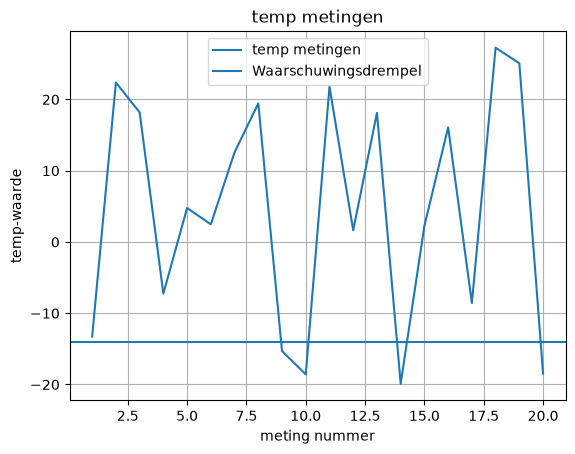

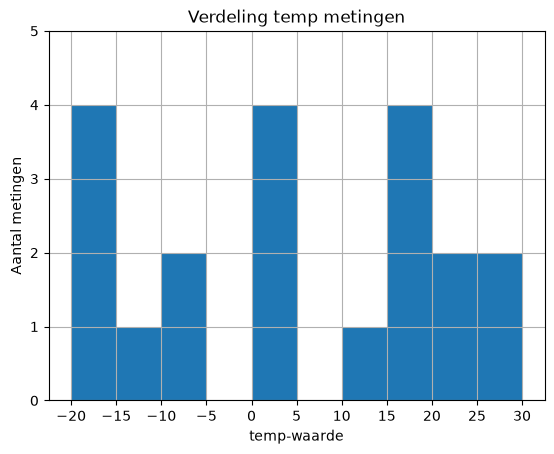

Aantal metingen: 20
Gemiddelde: 4.54
Minimum: -19.89
Maximum: 27.26
Standaardafwijking: 15.88
Aantal waarschuwingen: 16


In [35]:
import random
import numpy as np
import matplotlib.pyplot as plt
import csv

def getal_invoeren(vraag):
    getal = input(vraag)

    while True:
        try:
            getal = float(getal)
            break
        except ValueError:
            print("Voer een geldig getal in")
            getal = input(vraag)

    return getal

# 1. Gebruikers input
def gebruiker_input():
    type = input("Wat is er gemeten?: ")

    aantal = input("Hoeveel metingen heb je gedaan?: ")
    while not aantal.isdigit():
        print("Voer alleen cijfers in")
        aantal = input("Hoeveel metingen heb je gedaan?: ")
    aantal = int(aantal)

    Min = getal_invoeren("Minimale sensor waarde: ")
    Max = getal_invoeren("Maximale sensor waarde: ")
    

    while Min>= Max:
        print("Minimum moet kleiner zijn dan Maximum")

        Min = getal_invoeren("Minimale sensor waarde: ")
        Max = getal_invoeren("Maximale sensor waarde: ")

    richting = input("Waarschuwen boven of onder de drempel? (boven/onder): ")
    richting = richting.lower()
    while richting not in ["boven", "onder"]:
        print("Ongeldige keuze, kies boven of onder")
        richting = input("Waarschuwen boven of onder de drempel? (boven/onder): ")
        richting = richting.lower()

    Waarschuw = float(input("Waarschuwingsdrempel: "))

    
    
    return type, aantal, Min, Max, Waarschuw, richting

# 2. Random waardes
def waardes_genereren(aantal, minimum, maximum):
    random.seed(1)

    waardes = []

    for i in range(aantal):
        waarde = round(random.uniform(minimum, maximum), 2)
        waardes.append(waarde)

    return waardes

# 3. Uitschieters zoeken
def find_outliers(metingen, threshold, richting):

    uitschieters = []

    for meting in metingen:
        if richting == "boven" and meting > threshold:
            uitschieters.append(meting)

        elif richting == "onder" and meting < threshold:
            uitschieters.append(meting)

    return uitschieters

# 4. Data
def Analyze_NumPy(metingen, threshold, richting):
    metingen = np.array(metingen)
    aantal = len(metingen)
    gemiddelde = np.mean(metingen)
    minimum = np.min(metingen)
    maximum = np.max(metingen)
    standaardafwijking = np.std(metingen)
    
    if richting == "boven":
        aantal_waarschuwingen = np.sum(metingen > threshold)
    elif richting == "onder":
        aantal_waarschuwingen = np.sum(metingen < threshold)

    return aantal, gemiddelde, minimum, maximum, standaardafwijking, aantal_waarschuwingen

# 5. Grafiek
def Grafiek_maken(metingen, waarschuwingsdrempel, sensortype):
    plt.plot(range(1, len(metingen) + 1), metingen, label=f"{sensortype} metingen")
    plt.axhline(waarschuwingsdrempel, label="Waarschuwingsdrempel")

    plt.title(f"{sensortype} metingen")
    plt.xlabel("meting nummer")
    plt.ylabel(f"{sensortype}-waarde")
    plt.grid()
    plt.legend()
    plt.show()

# 6. Histogram maken
def histogram_maken(metingen, sensortype):
    minimum = int(min(metingen) // 5 * 5)
    maximum = int(max(metingen) // 5 * 5 + 5)

    bins = range(minimum, maximum + 5, 5)

    aantallen, _, _ = plt.hist(metingen, bins=bins)

    plt.title(f"Verdeling {sensortype} metingen")
    plt.xlabel(f"{sensortype}-waarde")
    plt.ylabel("Aantal metingen")
    plt.yticks(range(0, int(max(aantallen)) + 2))
    plt.xticks(bins)
    plt.grid()
    plt.show()

# 7. Data opslaan
def Opslaan(metingen, sensortype):
    with open("sensor_metingen.csv", "w", newline="") as bestand:
        schrijven = csv.writer(bestand)

        schrijven.writerow(["Meting nummer", f"{sensortype}waarde"])

        for i in range(len(metingen)):
            schrijven.writerow([i + 1, metingen[i]])

# 8. Hoofdprogramma
def main():
    
    sensortype, aantal, minimum, maximum, threshold, richting = gebruiker_input()
    waardes = waardes_genereren(aantal, minimum, maximum)
    uitschieters = find_outliers(waardes, threshold, richting)
    statistieken = Analyze_NumPy(waardes, threshold, richting)
    print("Uitschieters:", uitschieters)
    Opslaan(waardes, sensortype)
    Grafiek_maken(waardes, threshold, sensortype)
    histogram_maken(waardes, sensortype)

    print("Aantal metingen:", statistieken[0])
    print("Gemiddelde:", round(statistieken[1],2))
    print("Minimum:", statistieken[2])
    print("Maximum:", statistieken[3])
    print("Standaardafwijking:", round(statistieken[4],2))
    print("Aantal waarschuwingen:", statistieken[5])

# Programma starten
if __name__ == "__main__":
    main()
